# D04-KM — K-Means

Cấu hình: RFM + AOV + Diversity → winsorization P99 (F, M, AOV, Diversity; R giữ nguyên) → log1p → RobustScaler (IQR 25–75) → PCA 90%.

## Params

In [1]:
FEATURES = ['Recency', 'Frequency', 'Monetary', 'AOV', 'Diversity']
RANDOM_STATE = 42
CAP_Q = 99
N_INIT = 20
K_RANGE = range(2, 11)

## Import thư viện và đọc dữ liệu

In [2]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, RobustScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)

def find(rel):
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())

DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figures"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

RENAME = {"avg_order_value": "AOV", "n_stock_codes": "Diversity"}
df = pd.read_csv(DATA, dtype={"CustomerID": "string"}).rename(columns=RENAME)
X = df[FEATURES].astype(float)
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()
assert np.allclose(df["AOV"], df["Monetary"] / df["Frequency"], atol=0.01)
X_ALL = X.copy()
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 5)


,Recency,Frequency,Monetary,AOV,Diversity
count,4327.00,4327.00,4327.00,4327.00,4327.00
mean,93.04,4.25,1944.95,372.40,61.49
std,99.98,7.64,8441.89,466.49,85.31
min,1.00,1.00,2.90,2.90,1.00
25%,18.00,1.00,301.52,175.47,16.00
50%,51.00,2.00,657.90,286.70,35.00
75%,143.00,5.00,1624.10,421.99,77.00
max,374.00,206.00,278748.02,14844.77,1784.00


**Nhận xét:** 4,327 khách, 5 feature (Recency, Frequency, Monetary, AOV, Diversity), không thiếu giá trị và không có giá trị âm. Monetary lệch phải rất mạnh (trung vị 657.9, lớn nhất 278,748), nên winsorization và `log1p` ảnh hưởng nhiều đến kết quả.

## Winsorization ở cấp khách (không xóa khách)

In [3]:
caps = X.quantile(CAP_Q / 100)
caps["Recency"] = np.inf
capped = X.gt(caps, axis=1)
cap_report = pd.DataFrame({
    "cap": caps.replace(np.inf, np.nan).round(2),
    "customers_capped": capped.sum(),
    "customers_capped_pct": (100 * capped.mean()).round(2),
    "value_capped_pct": (100 * (X - X.clip(upper=caps, axis=1)).sum() / X.sum()).round(2),
})
print(f"Khách bị cap ở ít nhất 1 biến: {int(capped.any(axis=1).sum())} ({100 * capped.any(axis=1).mean():.2f}%) | không xóa khách nào")
cap_report

Khách bị cap ở ít nhất 1 biến: 116 (2.68%) | không xóa khách nào


,cap,customers_capped,customers_capped_pct,value_capped_pct
Recency,NaN,0,0.00,0.00
Frequency,30.00,42,0.97,6.12
Monetary,17279.06,44,1.02,21.62
AOV,1894.54,44,1.02,4.45
Diversity,353.74,44,1.02,3.50


**Nhận xét:** Cap ở phân vị 99: 116 khách (2.68%) bị cap ở ít nhất một biến; không xóa khách nào, Recency giữ nguyên. Monetary bị cắt nhiều giá trị nhất: 44 khách (1.02%) nhưng chiếm 21.62% tổng Monetary.

## Tiền xử lý

In [4]:
prep = Pipeline([
    ("cap", FunctionTransformer(np.clip, kw_args={"a_min": None, "a_max": caps.values})),
    ("log1p", FunctionTransformer(np.log1p)),
    ("scaler", RobustScaler(quantile_range=(25.0, 75.0))),
    ("pca", PCA(n_components=0.9, svd_solver="full", random_state=RANDOM_STATE)),
])
Z = prep.fit_transform(X.values)
print("Kích thước đầu vào mô hình:", Z.shape)
ev = prep["pca"].explained_variance_ratio_
print("Phương sai từng PC:", ev.round(4), "| giữ lại:", round(ev.sum(), 4))

Kích thước đầu vào mô hình: (4327, 3)
Phương sai từng PC: [0.6226 0.2163 0.0897] | giữ lại: 0.9287


**Nhận xét:** Đầu vào mô hình có 3 chiều (PCA giữ 92.87% phương sai; PC1 62.26%).

## Quét k = 2..10

Chọn k=2: Silhouette=0.3648, DBI=1.0333, CHI=3309.9, cụm nhỏ nhất=2058


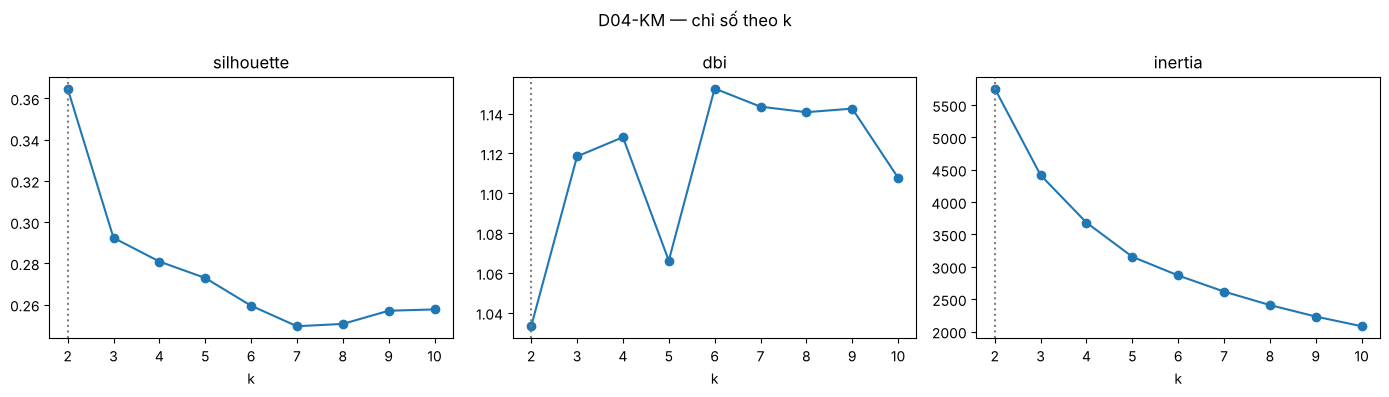

,k,silhouette,dbi,chi,inertia,min_cluster
0,2,0.3648,1.0333,3309.9198,5753.7833,2058
1,3,0.2924,1.1185,2811.1355,4415.7049,1111
2,4,0.2809,1.1281,2533.4702,3682.6361,961
3,5,0.2729,1.0662,2398.4159,3154.6524,711
4,6,0.2594,1.1526,2198.6358,2865.9108,478
5,7,0.2495,1.1435,2074.5528,2616.9558,249
6,8,0.2506,1.1407,1984.8591,2408.7250,224
7,9,0.2570,1.1425,1917.2687,2231.3018,200
8,10,0.2576,1.1078,1860.6712,2081.7696,154


In [5]:
rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=N_INIT, random_state=RANDOM_STATE).fit(Z)
    sizes = np.bincount(km.labels_, minlength=k)
    rows.append({"k": k, "silhouette": silhouette_score(Z, km.labels_), "dbi": davies_bouldin_score(Z, km.labels_),
                 "chi": calinski_harabasz_score(Z, km.labels_), "inertia": km.inertia_, "min_cluster": int(sizes.min())})
res = pd.DataFrame(rows)
best = res.loc[res["silhouette"].idxmax()]
print(f"Chọn k={int(best['k'])}: Silhouette={best['silhouette']:.4f}, DBI={best['dbi']:.4f}, CHI={best['chi']:.1f}, cụm nhỏ nhất={int(best['min_cluster'])}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["silhouette", "dbi", "inertia"]):
    ax.plot(res["k"], res[col], marker="o"); ax.axvline(int(best["k"]), color="gray", ls=":")
    ax.set_xlabel("k"); ax.set_title(col)
plt.suptitle("D04-KM — chỉ số theo k"); plt.tight_layout()
plt.savefig(FIG / "kmeans_metrics_by_k.png", dpi=150); plt.show()
res.round(4)

**Nhận xét:** Silhouette cao nhất ở k=2 (0.3648); DBI 1.0333, CHI 3309.9. Cụm nhỏ nhất có 2058 khách (47.56%).

## Train mô hình cuối

In [6]:
K = int(best["k"])
model = Pipeline([("prep", Pipeline([
        ("cap", FunctionTransformer(np.clip, kw_args={"a_min": None, "a_max": caps.values})),
        ("log1p", FunctionTransformer(np.log1p)),
        ("scaler", RobustScaler(quantile_range=(25.0, 75.0))),
        ("pca", PCA(n_components=0.9, svd_solver="full", random_state=RANDOM_STATE)),
    ])),
                  ("kmeans", KMeans(n_clusters=K, n_init=N_INIT, random_state=RANDOM_STATE))]).fit(X.values)
labels = model["kmeans"].labels_
assert np.allclose(model["prep"].transform(X.values), Z)
print("Số khách mỗi cụm:", dict(enumerate(np.bincount(labels).tolist())))
print("Silhouette:", round(silhouette_score(Z, labels), 4), "| DBI:", round(davies_bouldin_score(Z, labels), 4))

Số khách mỗi cụm: {0: 2269, 1: 2058}
Silhouette: 0.3648 | DBI: 1.0333


## Hồ sơ cụm

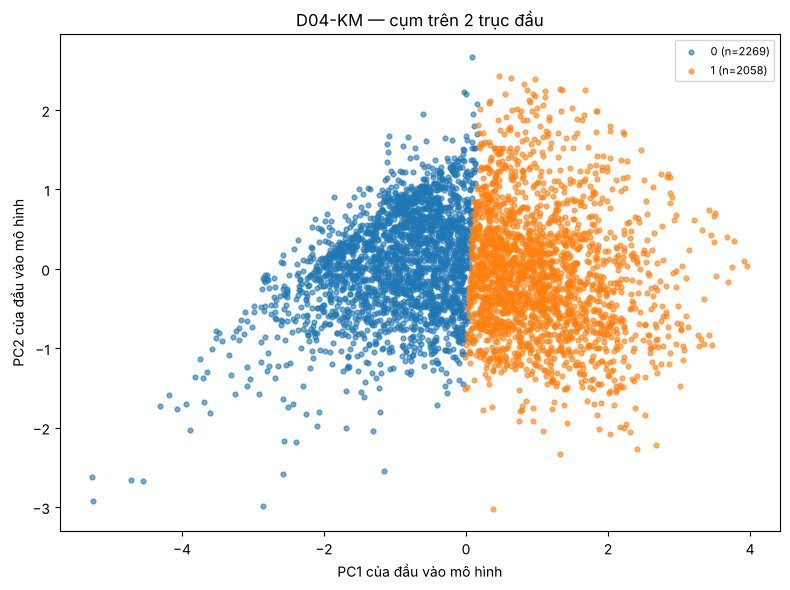

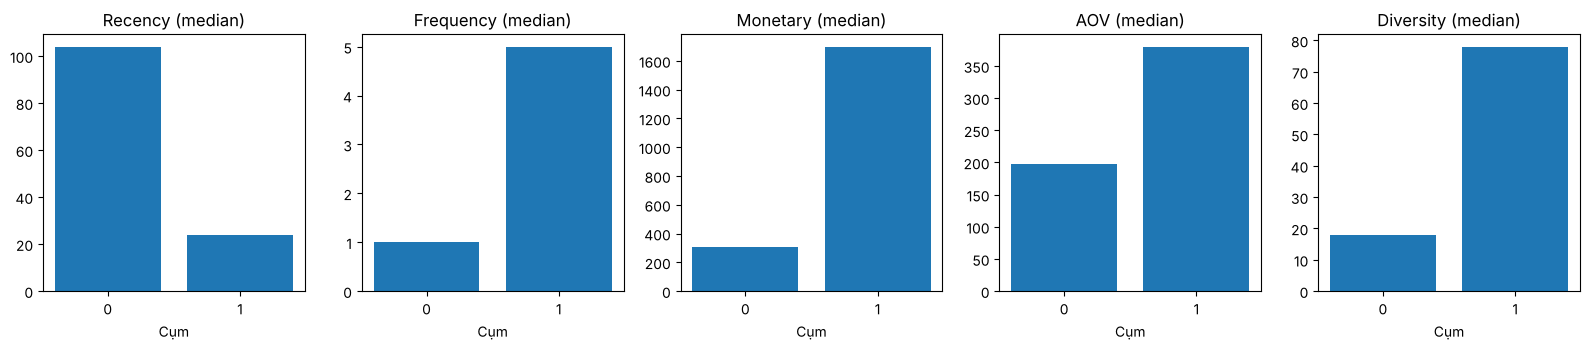

,customers,Recency,Frequency,Monetary,AOV,Diversity,customer_share_pct,Monetary_share_pct
cluster,,,,,,,,
0,2269,104.0,1.0,309.4,197.6,18.0,52.4,9.6
1,2058,24.0,5.0,1698.5,379.9,78.0,47.6,90.4


In [7]:
agg = {f: (f, "median") for f in FEATURES}
prof = X.assign(cluster=labels).groupby("cluster").agg(customers=("Monetary", "size"), Monetary_sum=("Monetary", "sum"), **agg)
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof = prof.drop(columns="Monetary_sum").round(1)

coords = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Z) if Z.shape[1] > 2 else Z
fig, ax = plt.subplots(figsize=(8, 6))
for c in sorted(np.unique(labels)):
    m = labels == c
    ax.scatter(coords[m, 0], coords[m, 1], s=12, alpha=0.6, marker="x" if c == -1 else "o", label=f"{c} (n={m.sum()})")
ax.set_xlabel("PC1 của đầu vào mô hình"); ax.set_ylabel("PC2 của đầu vào mô hình"); ax.legend(fontsize=8)
ax.set_title("D04-KM — cụm trên 2 trục đầu")
plt.tight_layout(); plt.savefig(FIG / "kmeans_clusters_pca.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, len(FEATURES), figsize=(3.2 * len(FEATURES), 3.6))
for ax, f in zip(axes, FEATURES):
    ax.bar(prof.index.astype(str), prof[f]); ax.set_title(f + " (median)"); ax.set_xlabel("Cụm")
plt.tight_layout(); plt.savefig(FIG / "feature_comparison.png", dpi=150); plt.show()
prof

**Nhận xét:** Cụm 1 có Monetary trung vị cao nhất (1,698), gồm 2058 khách (47.6%) nhưng chiếm 90.4% tổng Monetary. Cụm 0 đông nhất (52.4% khách, Recency trung vị 104 ngày).

## So với D01 (cùng tham số model)

In [8]:
PARENTS = {
    "D01": (99, None, "std", 0.9),
}

def build_parent(q, thr, scaler, pca):
    caps_p = X_ALL.quantile(q / 100)
    caps_p["Recency"] = np.inf
    feats = list(X_ALL.columns)
    if thr is not None:
        feats = [f for f in feats if f not in correlation_filter(X_ALL.clip(upper=caps_p, axis=1), thr)]
    steps = [("cap", FunctionTransformer(np.clip, kw_args={"a_min": None, "a_max": caps_p[feats].values})),
             ("log1p", FunctionTransformer(np.log1p)),
             ("scaler", StandardScaler() if scaler == "std" else RobustScaler(quantile_range=(25.0, 75.0)))]
    if pca:
        steps.append(("pca", PCA(n_components=pca, svd_solver="full", random_state=RANDOM_STATE)))
    return feats, Pipeline(steps)

rows = []
for name, (q, thr, scaler, pca) in PARENTS.items():
    feats_p, prep_p = build_parent(q, thr, scaler, pca)
    Zp = prep_p.fit_transform(X_ALL[feats_p].values)
    lp = KMeans(n_clusters=K, n_init=N_INIT, random_state=RANDOM_STATE).fit_predict(Zp)
    rows.append({"so với": name, "số feature": len(feats_p), "số chiều": Zp.shape[1],
                 "cùng tập feature": feats_p == FEATURES, "ARI": round(adjusted_rand_score(labels, lp), 4)})
parent_cmp = pd.DataFrame(rows)
parent_cmp

,so với,số feature,số chiều,cùng tập feature,ARI
0,D01,5,3,True,0.7806


**Nhận xét:** D04 (cùng tham số model): ARI với D01 = 0.7806. Thay đổi so với thí nghiệm gốc có tác động vừa phải đến phân cụm.

## Lưu kết quả

In [9]:
res.to_csv(OUT / "kmeans_d04_metrics_by_k.csv", index=False)
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels}).to_csv(OUT / "kmeans_d04_labels.csv", index=False)
cap_report.to_csv(OUT / "kmeans_d04_cap_report.csv")
joblib.dump(model, "kmeans_d04_model.pkl")
params = {"experiment": "D04-KM", "features": FEATURES, "feature_sources": {"AOV": "avg_order_value", "Diversity": "n_stock_codes"},
          "cap_percentile": CAP_Q, "caps": {k: (None if np.isinf(v) else float(v)) for k, v in caps.items()},
          "customers_capped": int(capped.any(axis=1).sum()),
          "transform": "log1p", "scaler": "RobustScaler(quantile_range=(25, 75))", "pca": 0.9,
          "n_components": int(Z.shape[1]), "n_customers": int(len(X)),
          "pca_variance_kept": float(model["prep"]["pca"].explained_variance_ratio_.sum()),
          "k": K, "silhouette": float(silhouette_score(Z, labels)), "dbi": float(davies_bouldin_score(Z, labels)),
          "chi": float(calinski_harabasz_score(Z, labels)), "inertia": float(model["kmeans"].inertia_), "n_init": N_INIT,
          "parent_comparison": parent_cmp.to_dict("records")}
json.dump(params, open(OUT / "kmeans_d04_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['kmeans_d04_cap_report.csv', 'kmeans_d04_labels.csv', 'kmeans_d04_metrics_by_k.csv', 'kmeans_d04_params.json']


**Kết luận D04-KM:** K-Means chọn k=2 (Silhouette 0.3648) trên 3 chiều đầu vào. ARI với D01 = 0.7806. Silhouette giữa các cấu hình có không gian đầu vào khác nhau (số chiều, scaler) không so sánh trực tiếp được; nên dựa vào ARI và hồ sơ cụm trên thang gốc.